# 1 - BM3D: classical baseline

**BM3D** (Block-Matching and 3D filtering) is the classic, *training-free* denoiser. It groups similar image patches into 3D stacks and filters them jointly in a transform domain. It needs no neural network and no GPU -- it is the baseline every deep method is compared against.

We start from a **CelebA-HQ face** corrupted with **additive white Gaussian noise** (sigma = 25/255). Every notebook in this tutorial uses the exact same image and noise, so the PSNR numbers are directly comparable across methods.

### Setup
`bm3d` is the only extra package; everything else ships with Colab.

In [1]:
!pip install -q bm3d scikit-image

### Load the CelebA face and add Gaussian noise

clean (256, 256, 3),  noise sigma = 0.098 (25/255)
noisy PSNR = 20.60 dB


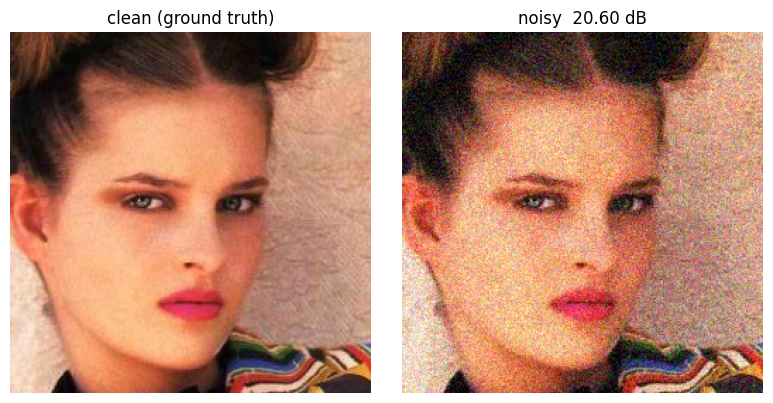

In [2]:
import io, requests, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Reproducibility
SEED  = 0
SIGMA = 25 / 255.0          # Gaussian noise std, on the [0, 1] intensity scale
IMG   = 256                 # all notebooks use 256x256 (matches the DDPM model)

def get_celeba_face(size=IMG, index=3):
    """Fetch a single CelebA-HQ face (256x256) via the HuggingFace datasets
    server. Falls back to a bundled skimage portrait if the download fails so
    the notebook always runs offline."""
    try:
        api = ("https://datasets-server.huggingface.co/first-rows?"
               "dataset=korexyz/celeba-hq-256x256&config=default&split=train")
        rows = requests.get(api, timeout=30).json()["rows"]
        src  = rows[index]["row"]["image"]["src"]
        img  = Image.open(io.BytesIO(requests.get(src, timeout=30).content))
    except Exception as e:
        print(f"[warn] CelebA download failed ({e}); using skimage sample face.")
        from skimage.data import astronaut
        img = Image.fromarray(astronaut())
    return img.convert("RGB").resize((size, size), Image.LANCZOS)

def psnr(a, b):
    """Peak signal-to-noise ratio for images in [0, 1]."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 100.0 if mse == 0 else 20 * np.log10(1.0 / np.sqrt(mse))

# Ground truth + noisy measurement -----------------------------------------
rng   = np.random.default_rng(SEED)
clean = np.asarray(get_celeba_face(), np.float32) / 255.0            # (H,W,3) in [0,1]
noisy = np.clip(clean + rng.normal(0, SIGMA, clean.shape), 0, 1).astype(np.float32)

print(f"clean {clean.shape},  noise sigma = {SIGMA:.3f} ({SIGMA*255:.0f}/255)")
print(f"noisy PSNR = {psnr(clean, noisy):.2f} dB")

def show(images, titles, suptitle=None):
    n = len(images)
    plt.figure(figsize=(4 * n, 4))
    for k, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, k + 1)
        plt.imshow(np.clip(im, 0, 1)); plt.title(t); plt.axis("off")
    if suptitle: plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

show([clean, noisy], ["clean (ground truth)", f"noisy  {psnr(clean, noisy):.2f} dB"])

### Denoise with BM3D
BM3D takes the noise standard deviation directly as input (`sigma_psd`). We use the colour variant `bm3d_rgb`.

In [3]:
import bm3d, time
t0 = time.time()
den = bm3d.bm3d_rgb(noisy, SIGMA)            # the whole algorithm in one call
den = np.clip(den, 0, 1).astype(np.float32)
print(f'BM3D done in {time.time()-t0:.1f}s')
print(f'noisy {psnr(clean, noisy):.2f} dB  ->  BM3D {psnr(clean, den):.2f} dB')

BM3D done in 1.9s
noisy 20.60 dB  ->  BM3D 31.92 dB


### Results

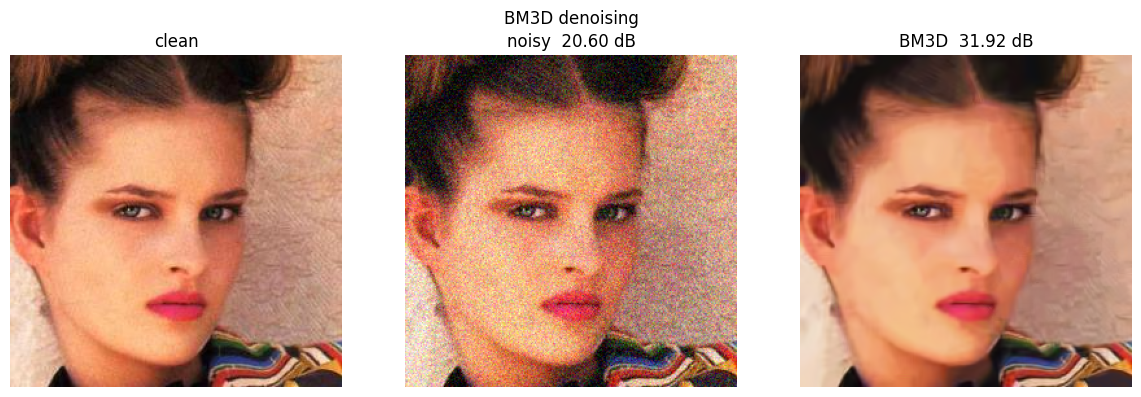

In [4]:
show([clean, noisy, den],
     ['clean', f'noisy  {psnr(clean, noisy):.2f} dB', f'BM3D  {psnr(clean, den):.2f} dB'],
     suptitle='BM3D denoising')

### Takeaways
* BM3D is a strong, *zero-training* baseline -- hard to beat on Gaussian noise.
* It **uses the known noise level** `sigma`. The self-supervised deep methods in the next notebooks do **not**.
* The remaining notebooks ask: can a small network learn to denoise from the noisy image alone (Noise2Void / Noise2Self), or from a pretrained generative prior (DPS)?

## Optional exercises

1. **Noise-level mismatch:** Keep `noisy` fixed and run `bm3d.bm3d_rgb` with `0.5 * SIGMA`, `SIGMA`, and `2 * SIGMA`. Compare PSNR and fine detail: which setting leaves noise, and which oversmooths?
2. **More noise:** Set `SIGMA = 50 / 255.0` in the data cell and rerun through Results. Compare the noisy and denoised PSNR with the original run. Which facial details become harder to recover?

## Try it on your own image

Upload **any** image -- colour or single-channel (e.g. a 16-bit microscopy TIFF), in **any** value range. `load_any` reads it, keeps 1 or 3 channels, and **min-max normalises it to [0, 1]**; very large images are downscaled so the longest side is at most `MAX_SIDE`.

Run the helper cell first, then the upload cell.

*Your image has no clean reference, so we simply show noisy vs. denoised (no PSNR).*

For BM3D we also need a **noise level**: we estimate it from the image with `estimate_sigma`, but you can set `MY_SIGMA` by hand if you know it.

In [5]:
from skimage.restoration import estimate_sigma

import os
from skimage.transform import resize as skresize

MAX_SIDE = 512   # large uploads are downscaled so the longest side <= MAX_SIDE

def load_any(path, max_side=MAX_SIDE):
    """Load a 1- or 3-channel image of ANY value range (8-bit, 16-bit TIFF,
    float, ...) and normalise it to float32 in [0, 1]. Returns (H, W, C)."""
    arr = np.asarray(Image.open(path)).astype(np.float32)
    if arr.ndim == 2:            # grayscale / single channel  -> (H, W, 1)
        arr = arr[..., None]
    else:                        # colour: keep up to 3 channels (drop alpha)
        arr = arr[..., :3]
    lo, hi = float(arr.min()), float(arr.max())
    arr = (arr - lo) / (hi - lo + 1e-8)                 # free range -> [0, 1]
    h, w = arr.shape[:2]
    if max_side and max(h, w) > max_side:
        s = max_side / max(h, w)
        arr = skresize(arr, (int(h*s), int(w*s), arr.shape[2]),
                       anti_aliasing=True).astype(np.float32)
    return arr.astype(np.float32)

def show_any(images, titles, suptitle=None):
    n = len(images); plt.figure(figsize=(5*n, 5))
    for k, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, k + 1)
        if im.shape[-1] == 1: plt.imshow(np.clip(im[..., 0], 0, 1), cmap="gray")
        else:                 plt.imshow(np.clip(im, 0, 1))
        plt.title(t); plt.axis("off")
    if suptitle: plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

In [6]:
import os
IMG_PATH = None
try:
    from google.colab import files            # Colab: opens an upload dialog
    IMG_PATH = list(files.upload().keys())[0]
except Exception:
    cand = 'your_image.tif'                    # not on Colab? set a local path here
    IMG_PATH = cand if os.path.exists(cand) else None

if IMG_PATH:
    img = load_any(IMG_PATH)
    C = img.shape[-1]
    print(f'loaded {IMG_PATH}: {img.shape}, normalised to [0, 1]')
    if C == 3:
        MY_SIGMA = float(estimate_sigma(img, channel_axis=-1, average_sigmas=True))
    else:
        MY_SIGMA = float(estimate_sigma(img[..., 0]))
    print(f'estimated noise sigma = {MY_SIGMA:.4f}')
    if C == 1:
        den = np.clip(bm3d.bm3d(img[..., 0], MY_SIGMA), 0, 1)[..., None]
    else:
        den = np.clip(bm3d.bm3d_rgb(img, MY_SIGMA), 0, 1)
    show_any([img, den], ['your image (noisy)', f'BM3D  (sigma={MY_SIGMA:.3f})'])
else:
    print('No image yet -> on Colab use the picker above, or set '
          'IMG_PATH to a local file and re-run this cell.')

No image yet -> on Colab use the picker above, or set IMG_PATH to a local file and re-run this cell.
